# Partie 1 — reprendre ta spécification

# Fiche technique d'une catégorie 


### Étape 1 — le périmètre

**Catégorie choisie :** Childrens (qui contient 29 livres sur deux pages)



### Étape 2 — le bloc qui se répète

Le sélecteur d'un bloc de livre est :  `<article class="product_pod">`.
Plus précidemment, c'est `article.product_pod`

Dans la console :

```js
document.querySelectorAll('article.product_pod').length
```

→ 20 (20 livres par page, normal).


### Étape 3 — le tableau des cinq données

| Donnée             | Sélecteur        | Contenu ou attribut ?                  |
| ------------------ | ---------------- | -------------------------------------- |
| titre              | `h3 a`           | attribut `title`                       |
| prix               | `p.price_color`  | contenu                                |
| disponibilité      | `p.availability` | contenu                                |
| note               | `p.star-rating`  | attribut `class` (2ᵉ mot : One à Five) |
| lien vers la fiche | `h3 a`           | attribut `href` (lien relatif)         |



### Étape 4 — deux sélecteurs testés

```js
document.querySelectorAll('article.product_pod p.price_color').length
```

→ 20

```js
document.querySelectorAll('article.product_pod h3 a').length
```

→ 20



### Étape 5 — Page suivante

- Sélecteur : `li.next a`, attribut `href`
- Valeur : `page-2.html` (lien relatif)

S'il y a une page suivante : 

```js
document.querySelector('li.next a').getAttribute('href')
```

→ `'page-2.html'`


S'il n'y a pas de page suivante :

```js
document.querySelector('li.next a')
```

→ `null`



### Étape 6 — Le contrôle du code source

Le premier livre de la catégorie « Childrens » vaut `£54.64`

- Prix cherché : `£54.64`
- Résultat : trouvé dans le code source de la page.
- Conséquence : la donnée est écrite directement dans le HTML envoyé par le serveur,
  donc un script qui télécharge la page avec `requests` la récupérera.
- Cas contraire : si le prix n'apparaissait pas dans le code source alors qu'il est
  visible dans l'inspecteur, c'est qu'il serait ajouté par du JavaScript après
  le chargement ; `requests` ne l'exécutant pas, le script repartirait sans la donnée.



### Étape 7 —  Des données de la fiche détaillée (absentes de la liste)



| Donnée        | Où                                                | Sélecteur                         | Contenu ou attribut ?                     |
| ------------- | ------------------------------------------------- | --------------------------------- | ----------------------------------------- |
| stock chiffré | tableau, ligne dont le `th` vaut « Availability » | `table.table-striped tr` → `td`   | contenu (ex. « In stock (22 available) ») |
| catégorie     | fil d'Ariane, 3ᵉ élément                          | `ul.breadcrumb li a` → le dernier | contenu (ex. « Childrens »)               |
| UPC           | tableau, ligne dont le `th` vaut « UPC »          | `table.table-striped tr` → `td`   | contenu (ex. « a897fe39b1053632 »)        |

# Partie 2 — une page, pour valider la chaîne (version préliminaire)

In [1]:
import requests
from bs4 import BeautifulSoup

URL = "https://books.toscrape.com/catalogue/category/books/childrens_11/index.html"
ENTETES = {"User-Agent": "bootcamp-data/1.0 (ton.email@exemple.fr)"}

r = requests.get(URL, headers=ENTETES, timeout=10)
r.encoding = "utf-8"   

soup = BeautifulSoup(r.text, "html.parser")


Collecte la première page seulement de ta catégorie. Construis un DataFrame avec titre, prix, dispo, note, url, puis affiche-le.

In [2]:
fiches = soup.select("article.product_pod")
print(len(fiches))
fiches[0]

20


<article class="product_pod">
<div class="image_container">
<a href="../../../birdsong-a-story-in-pictures_975/index.html"><img alt="Birdsong: A Story in Pictures" class="thumbnail" src="../../../../media/cache/af/6e/af6e796160fe63e0cf19d44395c7ddf2.jpg"/></a>
</div>
<p class="star-rating Three">
<i class="icon-star"></i>
<i class="icon-star"></i>
<i class="icon-star"></i>
<i class="icon-star"></i>
<i class="icon-star"></i>
</p>
<h3><a href="../../../birdsong-a-story-in-pictures_975/index.html" title="Birdsong: A Story in Pictures">Birdsong: A Story in ...</a></h3>
<div class="product_price">
<p class="price_color">£54.64</p>
<p class="instock availability">
<i class="icon-ok"></i>
    
        In stock
    
</p>
<form>
<button class="btn btn-primary btn-block" data-loading-text="Adding..." type="submit">Add to basket</button>
</form>
</div>
</article>

In [3]:
fiche = fiches[0]

In [4]:
titre = fiche.select_one('h3 a')['title']
print(f"Titre : {titre}")

Titre : Birdsong: A Story in Pictures


In [5]:
prix = fiche.select_one('p.price_color').get_text(strip=True) 
print(f"Prix : {prix}")

Prix : £54.64


In [6]:
dispo = fiche.select_one('p.availability').get_text(strip=True)
print(f"Dispo : {dispo}")

Dispo : In stock


In [7]:
NOTES = {"One": 1, "Two": 2, "Three": 3, "Four": 4, "Five": 5}
note_texte = fiche.select_one('p.star-rating')['class'][1]
note = NOTES[note_texte]
print(f"Note : {note}")

Note : 3


In [8]:
url_relative = fiche.select_one('h3 a')['href']

In [9]:
from urllib.parse import urljoin

url = urljoin(URL, url_relative)
url

'https://books.toscrape.com/catalogue/birdsong-a-story-in-pictures_975/index.html'

# Partie 2 — Une page, pour valider la chaîne (version intermédiaire)

In [10]:
import requests
from bs4 import BeautifulSoup
from urllib.parse import urljoin
from pprint import pprint
import pandas as pd

URL = "https://books.toscrape.com/catalogue/category/books/childrens_11/index.html"
ENTETES = {"User-Agent": "bootcamp-data/1.0 (ton.email@exemple.fr)"}
NOTES = {"One": 1, "Two": 2, "Three": 3, "Four": 4, "Five": 5}

r = requests.get(URL, headers=ENTETES, timeout=10)
r.encoding = "utf-8"   

soup = BeautifulSoup(r.text, "html.parser")
fiches = soup.select("article.product_pod")

In [11]:
liste_de_livres = []
for fiche in fiches:
    titre = fiche.select_one('h3 a')['title']
    prix = fiche.select_one('p.price_color').get_text(strip=True)
    dispo = fiche.select_one('p.availability').get_text(strip=True)
    note_texte = fiche.select_one('p.star-rating')['class'][1]
    note = NOTES[note_texte]
    url_relative = fiche.select_one('h3 a')['href']
    url = urljoin(URL, url_relative)
    dict_du_livre = {
        'titre': titre,
        'prix': prix,
        'dispo': dispo,
        'note': note,
        'url': url
    }
    liste_de_livres.append(dict_du_livre)
    #pprint(dict_du_livre)
df_page1 = pd.DataFrame(liste_de_livres)

In [12]:
df_page1

,titre,prix,dispo,note,url
0,Birdsong: A Story in Pictures,£54.64,In stock,3,https://books.toscrape.com/catalogue/birdsong-...
1,The Bear and the Piano,£36.89,In stock,1,https://books.toscrape.com/catalogue/the-bear-...
2,The Secret of Dreadwillow Carse,£56.13,In stock,1,https://books.toscrape.com/catalogue/the-secre...
3,The White Cat and the Monk: A Retelling of the...,£58.08,In stock,4,https://books.toscrape.com/catalogue/the-white...
4,Little Red,£13.47,In stock,3,https://books.toscrape.com/catalogue/little-re...
5,Walt Disney's Alice in Wonderland,£12.96,In stock,5,https://books.toscrape.com/catalogue/walt-disn...
6,Twenty Yawns,£22.08,In stock,2,https://books.toscrape.com/catalogue/twenty-ya...
7,Rain Fish,£23.57,In stock,3,https://books.toscrape.com/catalogue/rain-fish...
8,Once Was a Time,£18.28,In stock,2,https://books.toscrape.com/catalogue/once-was-...
9,Luis Paints the World,£53.95,In stock,3,https://books.toscrape.com/catalogue/luis-pain...


# Partie 2 — Une page, pour valider la chaîne (version finale avec fonction)

In [13]:
import requests
from bs4 import BeautifulSoup
from urllib.parse import urljoin
from pprint import pprint
import pandas as pd

URL = "https://books.toscrape.com/catalogue/category/books/childrens_11/index.html"
ENTETES = {"User-Agent": "bootcamp-data/1.0 (ton.email@exemple.fr)"}

r = requests.get(URL, headers=ENTETES, timeout=10)
r.encoding = "utf-8"   

soup = BeautifulSoup(r.text, "html.parser")
fiches = soup.select("article.product_pod")

In [14]:
def lire_fiche(fiche, base_url):
    NOTES = {"One": 1, "Two": 2, "Three": 3, "Four": 4, "Five": 5}
    titre = fiche.select_one('h3 a')['title']
    prix = fiche.select_one('p.price_color').get_text(strip=True)
    dispo = fiche.select_one('p.availability').get_text(strip=True)
    note_texte = fiche.select_one('p.star-rating')['class'][1]
    note = NOTES[note_texte]
    relat_url = fiche.select_one('h3 a')['href']
    url = urljoin(base_url, relat_url)   
    dict_du_livre = {
            'titre': titre,
            'prix': prix,
            'dispo': dispo,
            'note': note,
            'url': url
        }
    return dict_du_livre

In [15]:
lire_fiche(fiches[0], URL)

{'titre': 'Birdsong: A Story in Pictures',
 'prix': '£54.64',
 'dispo': 'In stock',
 'note': 3,
 'url': 'https://books.toscrape.com/catalogue/birdsong-a-story-in-pictures_975/index.html'}

In [16]:
liste_de_livres = []
for fiche in fiches:
    un_livre = lire_fiche(fiche, URL)
    liste_de_livres.append(un_livre)
df_page1 = pd.DataFrame(liste_de_livres)
df_page1

,titre,prix,dispo,note,url
0,Birdsong: A Story in Pictures,£54.64,In stock,3,https://books.toscrape.com/catalogue/birdsong-...
1,The Bear and the Piano,£36.89,In stock,1,https://books.toscrape.com/catalogue/the-bear-...
2,The Secret of Dreadwillow Carse,£56.13,In stock,1,https://books.toscrape.com/catalogue/the-secre...
3,The White Cat and the Monk: A Retelling of the...,£58.08,In stock,4,https://books.toscrape.com/catalogue/the-white...
4,Little Red,£13.47,In stock,3,https://books.toscrape.com/catalogue/little-re...
5,Walt Disney's Alice in Wonderland,£12.96,In stock,5,https://books.toscrape.com/catalogue/walt-disn...
6,Twenty Yawns,£22.08,In stock,2,https://books.toscrape.com/catalogue/twenty-ya...
7,Rain Fish,£23.57,In stock,3,https://books.toscrape.com/catalogue/rain-fish...
8,Once Was a Time,£18.28,In stock,2,https://books.toscrape.com/catalogue/once-was-...
9,Luis Paints the World,£53.95,In stock,3,https://books.toscrape.com/catalogue/luis-pain...


# Partie 3 — toutes les pages de liste

In [17]:
%reset -f

In [18]:
import requests
from bs4 import BeautifulSoup
from urllib.parse import urljoin
from pprint import pprint
import pandas as pd
import time

# r = requests.get(URL, headers=ENTETES, timeout=10)
# r.encoding = "utf-8"   

# soup = BeautifulSoup(r.text, "html.parser")
# fiches = soup.select("article.product_pod")

In [19]:
def lire_fiche(fiche, base_url):
    """
    Fonction utilitaire qui prend la fiche d'un livre et l'URL de base
    et qui renvoie un dictionnaire correspondant à ce livre sous la forme :
    {
        'titre': titre,
        'prix': prix,
        'dispo': dispo,
        'note': note,
        'url': url
    }
    """
    NOTES = {"One": 1, "Two": 2, "Three": 3, "Four": 4, "Five": 5}
    titre = fiche.select_one('h3 a')['title']
    prix = fiche.select_one('p.price_color').get_text(strip=True)
    dispo = fiche.select_one('p.availability').get_text(strip=True)
    note_texte = fiche.select_one('p.star-rating')['class'][1]
    note = NOTES[note_texte]
    relat_url = fiche.select_one('h3 a')['href']
    url = urljoin(base_url, relat_url)   
    dict_du_livre = {
        'titre': titre,
        'prix': prix,
        'dispo': dispo,
        'note': note,
        'url': url
    }
    return dict_du_livre

In [20]:
def toutes_les_pages(start_url, page_max=3):
    """
    Cette fonction prend en entrée l'URL qui correspond à une catégorie
    sur books.toscrape.com. Par exemple :
    start_url = "https://books.toscrape.com/catalogue/category/books/childrens_11/index.html"
    Il y a aussi un un argument optionnel page_max (qui vaut 3 par défaut) qui indique 
    combien de pages (de 20 livres maximum chacune) seront traitées. 
    Si le nombre théorique de livres sur le site différe de ce qui est récolté, il 
    convient d'augmenter ce paramètre.
    Cette fonction retourne une liste de dictionnaires, chaque dictionnaire
    correpondant à un livre sous la forme :
    {
        'titre': titre,
        'prix': prix,
        'dispo': dispo,
        'note': note,
        'url': url
    }
    """
    ENTETES = {"User-Agent": "bootcamp-data/1.0 (ton.email@exemple.fr)"}
    nb_page = 0
    url_courante = start_url
    tous_les_livres = []
    print("Début de la collecte")
    while url_courante and nb_page < page_max:
        nb_page += 1 
        r = requests.get(url_courante, headers=ENTETES, timeout=10)
        r.encoding = "utf-8"  
        if r.status_code != 200:
            print(f"Page {nb_page} : status {r.status_code}, on s'arrete")
            break 
        soup = BeautifulSoup(r.text, "html.parser")
        fiches = soup.select("article.product_pod")
        for fiche in fiches:
            tous_les_livres.append(lire_fiche(fiche, url_courante))     
        print(f"  page {nb_page} : {len(fiches)} livres  (total {len(tous_les_livres)})")
        # passage éventuel à la page suivante
        suivant = soup.select_one("li.next a")   
        if suivant:
            url_courante = urljoin(url_courante, suivant['href'])
        else:
            url_courante = None
        time.sleep(1)
    print(f"Collecte terminée : {len(tous_les_livres)} livres")    
    return tous_les_livres

In [21]:
def demo_question_3(URL, nb_livres_sur_le_site, page_max=3):
    print(f"Nombre de livres annoncé sur le site : {nb_livres_sur_le_site}")
    livres = toutes_les_pages(URL, page_max)
    df_total = pd.DataFrame(livres)
    print(f"Taille du DataFrame : {len(df_total)}")
    verif = nb_livres_sur_le_site == len(df_total)
    print(f"Le nombre de livres sur le site est égal au nombre de livres récoltés : {verif}")
    return df_total

In [22]:
URL = "https://books.toscrape.com/catalogue/category/books/childrens_11/index.html"
nb_livres_sur_le_site = 29
demo_question_3(URL, nb_livres_sur_le_site)

Nombre de livres annoncé sur le site : 29
Début de la collecte
  page 1 : 20 livres  (total 20)
  page 2 : 9 livres  (total 29)
Collecte terminée : 29 livres
Taille du DataFrame : 29
Le nombre de livres sur le site est égal au nombre de livres récoltés : True


,titre,prix,dispo,note,url
0,Birdsong: A Story in Pictures,£54.64,In stock,3,https://books.toscrape.com/catalogue/birdsong-...
1,The Bear and the Piano,£36.89,In stock,1,https://books.toscrape.com/catalogue/the-bear-...
2,The Secret of Dreadwillow Carse,£56.13,In stock,1,https://books.toscrape.com/catalogue/the-secre...
3,The White Cat and the Monk: A Retelling of the...,£58.08,In stock,4,https://books.toscrape.com/catalogue/the-white...
4,Little Red,£13.47,In stock,3,https://books.toscrape.com/catalogue/little-re...
5,Walt Disney's Alice in Wonderland,£12.96,In stock,5,https://books.toscrape.com/catalogue/walt-disn...
6,Twenty Yawns,£22.08,In stock,2,https://books.toscrape.com/catalogue/twenty-ya...
7,Rain Fish,£23.57,In stock,3,https://books.toscrape.com/catalogue/rain-fish...
8,Once Was a Time,£18.28,In stock,2,https://books.toscrape.com/catalogue/once-was-...
9,Luis Paints the World,£53.95,In stock,3,https://books.toscrape.com/catalogue/luis-pain...


In [23]:
URL = "https://books.toscrape.com/catalogue/category/books/music_14/index.html"
nb_livres_sur_le_site = 13
demo_question_3(URL, nb_livres_sur_le_site)

Nombre de livres annoncé sur le site : 13
Début de la collecte
  page 1 : 13 livres  (total 13)
Collecte terminée : 13 livres
Taille du DataFrame : 13
Le nombre de livres sur le site est égal au nombre de livres récoltés : True


,titre,prix,dispo,note,url
0,Rip it Up and Start Again,£35.02,In stock,5,https://books.toscrape.com/catalogue/rip-it-up...
1,Our Band Could Be Your Life: Scenes from the A...,£57.25,In stock,3,https://books.toscrape.com/catalogue/our-band-...
2,How Music Works,£37.32,In stock,2,https://books.toscrape.com/catalogue/how-music...
3,Love Is a Mix Tape (Music #1),£18.03,In stock,1,https://books.toscrape.com/catalogue/love-is-a...
4,Please Kill Me: The Uncensored Oral History of...,£31.19,In stock,4,https://books.toscrape.com/catalogue/please-ki...
5,Kill 'Em and Leave: Searching for James Brown ...,£45.05,In stock,5,https://books.toscrape.com/catalogue/kill-em-a...
6,"Chronicles, Vol. 1",£52.60,In stock,2,https://books.toscrape.com/catalogue/chronicle...
7,This Is Your Brain on Music: The Science of a ...,£38.40,In stock,1,https://books.toscrape.com/catalogue/this-is-y...
8,Orchestra of Exiles: The Story of Bronislaw Hu...,£12.36,In stock,3,https://books.toscrape.com/catalogue/orchestra...
9,No One Here Gets Out Alive,£20.02,In stock,5,https://books.toscrape.com/catalogue/no-one-he...


In [24]:
URL = "https://books.toscrape.com/catalogue/category/books/sequential-art_5/index.html"
nb_livres_sur_le_site = 75
demo_question_3(URL, nb_livres_sur_le_site)

Nombre de livres annoncé sur le site : 75
Début de la collecte
  page 1 : 20 livres  (total 20)
  page 2 : 20 livres  (total 40)
  page 3 : 20 livres  (total 60)
Collecte terminée : 60 livres
Taille du DataFrame : 60
Le nombre de livres sur le site est égal au nombre de livres récoltés : False


,titre,prix,dispo,note,url
0,Scott Pilgrim's Precious Little Life (Scott Pi...,£52.29,In stock,5,https://books.toscrape.com/catalogue/scott-pil...
1,Tsubasa: WoRLD CHRoNiCLE 2 (Tsubasa WoRLD CHRo...,£16.28,In stock,1,https://books.toscrape.com/catalogue/tsubasa-w...
2,This One Summer,£19.49,In stock,4,https://books.toscrape.com/catalogue/this-one-...
3,The Nameless City (The Nameless City #1),£38.16,In stock,4,https://books.toscrape.com/catalogue/the-namel...
4,"Saga, Volume 5 (Saga (Collected Editions) #5)",£51.04,In stock,2,https://books.toscrape.com/catalogue/saga-volu...
5,"Rat Queens, Vol. 3: Demons (Rat Queens (Collec...",£50.40,In stock,3,https://books.toscrape.com/catalogue/rat-queen...
6,"Princess Jellyfish 2-in-1 Omnibus, Vol. 01 (Pr...",£13.61,In stock,5,https://books.toscrape.com/catalogue/princess-...
7,"Pop Gun War, Volume 1: Gift",£18.97,In stock,1,https://books.toscrape.com/catalogue/pop-gun-w...
8,Patience,£10.16,In stock,3,https://books.toscrape.com/catalogue/patience_...
9,"Outcast, Vol. 1: A Darkness Surrounds Him (Out...",£15.44,In stock,4,https://books.toscrape.com/catalogue/outcast-v...


La celellule précédente est un exemple où le nombre de pages maximum traitées n'est pas suffisant.
Pour 75 = 20 + 20 + 20 + 15 il faut 4 pages et pas seulement 3.

In [25]:
URL = "https://books.toscrape.com/catalogue/category/books/sequential-art_5/index.html"
nb_livres_sur_le_site = 75
demo_question_3(URL, nb_livres_sur_le_site, 4)

Nombre de livres annoncé sur le site : 75
Début de la collecte
  page 1 : 20 livres  (total 20)
  page 2 : 20 livres  (total 40)
  page 3 : 20 livres  (total 60)
  page 4 : 15 livres  (total 75)
Collecte terminée : 75 livres
Taille du DataFrame : 75
Le nombre de livres sur le site est égal au nombre de livres récoltés : True


,titre,prix,dispo,note,url
0,Scott Pilgrim's Precious Little Life (Scott Pi...,£52.29,In stock,5,https://books.toscrape.com/catalogue/scott-pil...
1,Tsubasa: WoRLD CHRoNiCLE 2 (Tsubasa WoRLD CHRo...,£16.28,In stock,1,https://books.toscrape.com/catalogue/tsubasa-w...
2,This One Summer,£19.49,In stock,4,https://books.toscrape.com/catalogue/this-one-...
3,The Nameless City (The Nameless City #1),£38.16,In stock,4,https://books.toscrape.com/catalogue/the-namel...
4,"Saga, Volume 5 (Saga (Collected Editions) #5)",£51.04,In stock,2,https://books.toscrape.com/catalogue/saga-volu...
...,...,...,...,...,...
70,"Hawkeye, Vol. 1: My Life as a Weapon (Hawkeye #1)",£45.24,In stock,3,https://books.toscrape.com/catalogue/hawkeye-v...
71,"Giant Days, Vol. 1 (Giant Days #1-4)",£56.76,In stock,4,https://books.toscrape.com/catalogue/giant-day...
72,"Fruits Basket, Vol. 1 (Fruits Basket #1)",£40.28,In stock,5,https://books.toscrape.com/catalogue/fruits-ba...
73,"Bleach, Vol. 1: Strawberry and the Soul Reaper...",£34.65,In stock,5,https://books.toscrape.com/catalogue/bleach-vo...


# Partie 4 — le second niveau

In [26]:
def chaine_en_nombre(texte):
    if texte is None:
        return None
    else:
        nombre = ""
        for c in texte:
            if c in "0123456789":
                nombre += c
    if nombre == "":
        return 0
    else:
        return int(nombre)

In [27]:
print(chaine_en_nombre("In stock (19 available)"))
print(chaine_en_nombre("Out of stock"))
print(chaine_en_nombre(None))

19
0
None


In [28]:
def recuperer_details(url):
    """
    Cette fonction prend en entrée l'URL d'un livre spécifique, par exemple :
    "https://books.toscrape.com/catalogue/birdsong-a-story-in-pictures_975/index.html"    
    et renvoie sous la forme d'un dictionnaire quelques propriétés supplémentaires
    concernant ce livre (qui n'étaient pas nécessairement sur la page principale).
    Précisément, la sortie est un dictionnaire de la forme :
    {
        'categorie': categorie,
        'stock': stock,
        'upc': upc
    }    
    """
    ENTETES = {"User-Agent": "bootcamp-data/1.0 (ton.email@exemple.fr)"}
    r = requests.get(url, headers=ENTETES, timeout=10)
    r.encoding = "utf-8"
    if r.status_code != 200:
        return {"categorie": None, "stock": None, "upc": None}        
    soup = BeautifulSoup(r.text, "html.parser")    
    
    # la categorie : troisieme element du fil d'Ariane
    navigation = soup.select("ul.breadcrumb li a")
    categorie = navigation[-1].get_text(strip=True) if navigation else None

    # le tableau : une entree par ligne, le th en cle et le td en valeur

    tableau = soup.select("table.table-striped tr")
    informations = {}
    for ligne in tableau:
        label = ligne.select_one('th')
        value = ligne.select_one('td')
        if label and value:
            informations[label.get_text(strip=True)] = value.get_text(strip=True)
    upc = informations.get('UPC')
    phrase_stock = informations.get('Availability')
    stock = chaine_en_nombre(phrase_stock)
    res = {'categorie': categorie,
           'stock': stock,
           'upc': upc
           }
    return res
    

In [29]:
URL = "https://books.toscrape.com/catalogue/birdsong-a-story-in-pictures_975/index.html"
recuperer_details(URL)

{'categorie': 'Childrens', 'stock': 19, 'upc': '9528d0948525bf5f'}

In [30]:
start_url = "https://books.toscrape.com/catalogue/category/books/childrens_11/index.html"
livres = toutes_les_pages(start_url, page_max=3)

Début de la collecte
  page 1 : 20 livres  (total 20)
  page 2 : 9 livres  (total 29)
Collecte terminée : 29 livres


# Partie 5 -  assembler et nettoyer

In [31]:
def assemblage_final(start_url, page_max=3):

    livres = toutes_les_pages(start_url, page_max)
    print("Début de l'assemblage final")
    liste_de_dico = []
    nb_livres = len(livres)                                # <- ajout
    compteur = 0                                           # <- ajout
    for livre in livres:
        compteur += 1                                      # <- ajout
        print(f"  livre {compteur}/{nb_livres} : {livre['titre']}")   # <- ajout
        url = livre['url']
        details = recuperer_details(url)
        time.sleep(1)
        titre = livre['titre']
        categorie = details['categorie']
        prix_gbp = float(livre['prix'].replace('£', ''))
        note = livre['note']
        stock = details['stock']
        upc = details['upc']
        res = {'titre': titre,
               'categorie': categorie,
               'prix_gbp': prix_gbp,
               'note': note,
               'stock': stock,
               'upc': upc,
               'url': url
        }
        liste_de_dico.append(res)
    print("Fin de l'assemblage final")
    return pd.DataFrame(liste_de_dico)

In [32]:
start_url = "https://books.toscrape.com/catalogue/category/books/childrens_11/index.html"
df_childrens = assemblage_final(start_url, page_max=4)

Début de la collecte
  page 1 : 20 livres  (total 20)
  page 2 : 9 livres  (total 29)
Collecte terminée : 29 livres
Début de l'assemblage final
  livre 1/29 : Birdsong: A Story in Pictures
  livre 2/29 : The Bear and the Piano
  livre 3/29 : The Secret of Dreadwillow Carse
  livre 4/29 : The White Cat and the Monk: A Retelling of the Poem “Pangur Bán”
  livre 5/29 : Little Red
  livre 6/29 : Walt Disney's Alice in Wonderland
  livre 7/29 : Twenty Yawns
  livre 8/29 : Rain Fish
  livre 9/29 : Once Was a Time
  livre 10/29 : Luis Paints the World
  livre 11/29 : Nap-a-Roo
  livre 12/29 : The Whale
  livre 13/29 : Shrunken Treasures: Literary Classics, Short, Sweet, and Silly
  livre 14/29 : Raymie Nightingale
  livre 15/29 : Playing from the Heart
  livre 16/29 : Maybe Something Beautiful: How Art Transformed a Neighborhood
  livre 17/29 : The Wild Robot
  livre 18/29 : The Thing About Jellyfish
  livre 19/29 : The Lonely Ones
  livre 20/29 : The Day the Crayons Came Home (Crayons)
  liv

In [33]:
start_url = 'https://books.toscrape.com/catalogue/category/books/fantasy_19/index.html'
df_fantasy = assemblage_final(start_url, page_max=4)

Début de la collecte
  page 1 : 20 livres  (total 20)
  page 2 : 20 livres  (total 40)
  page 3 : 8 livres  (total 48)
Collecte terminée : 48 livres
Début de l'assemblage final
  livre 1/48 : Unicorn Tracks
  livre 2/48 : Saga, Volume 6 (Saga (Collected Editions) #6)
  livre 3/48 : Princess Between Worlds (Wide-Awake Princess #5)
  livre 4/48 : Masks and Shadows
  livre 5/48 : Crown of Midnight (Throne of Glass #2)
  livre 6/48 : Avatar: The Last Airbender: Smoke and Shadow, Part 3 (Smoke and Shadow #3)
  livre 7/48 : A Court of Thorns and Roses (A Court of Thorns and Roses #1)
  livre 8/48 : Throne of Glass (Throne of Glass #1)
  livre 9/48 : The Glittering Court (The Glittering Court #1)
  livre 10/48 : Hollow City (Miss Peregrine’s Peculiar Children #2)
  livre 11/48 : The Star-Touched Queen
  livre 12/48 : The Hidden Oracle (The Trials of Apollo #1)
  livre 13/48 : The Bane Chronicles (The Bane Chronicles #1-11)
  livre 14/48 : Island of Dragons (Unwanteds #7)
  livre 15/48 : Demig

In [34]:
df_childrens

,titre,categorie,prix_gbp,note,stock,upc,url
0,Birdsong: A Story in Pictures,Childrens,54.64,3,19,9528d0948525bf5f,https://books.toscrape.com/catalogue/birdsong-...
1,The Bear and the Piano,Childrens,36.89,1,18,9f6568e9c95f60b0,https://books.toscrape.com/catalogue/the-bear-...
2,The Secret of Dreadwillow Carse,Childrens,56.13,1,16,b5ea0b5dabed25a8,https://books.toscrape.com/catalogue/the-secre...
3,The White Cat and the Monk: A Retelling of the...,Childrens,58.08,4,15,37c0cb19713d8dda,https://books.toscrape.com/catalogue/the-white...
4,Little Red,Childrens,13.47,3,15,4aa03792b50f0b22,https://books.toscrape.com/catalogue/little-re...
5,Walt Disney's Alice in Wonderland,Childrens,12.96,5,14,6a31307a81e8f3a8,https://books.toscrape.com/catalogue/walt-disn...
6,Twenty Yawns,Childrens,22.08,2,14,1d6443ffba9dfd80,https://books.toscrape.com/catalogue/twenty-ya...
7,Rain Fish,Childrens,23.57,3,14,a6454e329f872b78,https://books.toscrape.com/catalogue/rain-fish...
8,Once Was a Time,Childrens,18.28,2,14,e34efcc824685332,https://books.toscrape.com/catalogue/once-was-...
9,Luis Paints the World,Childrens,53.95,3,14,5b43cae640f2338a,https://books.toscrape.com/catalogue/luis-pain...


In [35]:
df_fantasy

,titre,categorie,prix_gbp,note,stock,upc,url
0,Unicorn Tracks,Fantasy,18.78,3,16,7ae099f3898e0209,https://books.toscrape.com/catalogue/unicorn-t...
1,"Saga, Volume 6 (Saga (Collected Editions) #6)",Fantasy,25.02,3,16,c849f0b2f5d6a742,https://books.toscrape.com/catalogue/saga-volu...
2,Princess Between Worlds (Wide-Awake Princess #5),Fantasy,13.34,5,16,0e691eda369f4e09,https://books.toscrape.com/catalogue/princess-...
3,Masks and Shadows,Fantasy,56.40,2,16,fa9610a50a1bf149,https://books.toscrape.com/catalogue/masks-and...
4,Crown of Midnight (Throne of Glass #2),Fantasy,43.29,3,16,7267864328ae8b9d,https://books.toscrape.com/catalogue/crown-of-...
5,"Avatar: The Last Airbender: Smoke and Shadow, ...",Fantasy,28.09,2,16,6d5300b2d8f37e07,https://books.toscrape.com/catalogue/avatar-th...
6,A Court of Thorns and Roses (A Court of Thorns...,Fantasy,52.37,1,16,01d2001ac1e6f8a3,https://books.toscrape.com/catalogue/a-court-o...
7,Throne of Glass (Throne of Glass #1),Fantasy,35.07,3,15,590a9cccf7db9f7d,https://books.toscrape.com/catalogue/throne-of...
8,The Glittering Court (The Glittering Court #1),Fantasy,44.28,1,15,2dbb7ec08cdd7f3c,https://books.toscrape.com/catalogue/the-glitt...
9,Hollow City (Miss Peregrine’s Peculiar Childre...,Fantasy,42.98,1,15,4ce91d31c1e57c33,https://books.toscrape.com/catalogue/hollow-ci...


In [36]:
df_fantasy.info()

<class 'pandas.DataFrame'>
RangeIndex: 48 entries, 0 to 47
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   titre      48 non-null     str    
 1   categorie  48 non-null     str    
 2   prix_gbp   48 non-null     float64
 3   note       48 non-null     int64  
 4   stock      48 non-null     int64  
 5   upc        48 non-null     str    
 6   url        48 non-null     str    
dtypes: float64(1), int64(2), str(4)
memory usage: 2.8 KB


# Partie 6 - Vérifications (faites pour les catégories 'Childrens' et 'Fantasy')

In [37]:
print("Catégorie 'Childrens'")
nb_livres_sur_le_site = 29
taille_du_dataframe = len(df_childrens)
print(f"nb_livres_sur_le_site : {nb_livres_sur_le_site} ")
print(f"taille_du_dataframe : {taille_du_dataframe} ")
print(f"Vérification : {taille_du_dataframe == nb_livres_sur_le_site}")

Catégorie 'Childrens'
nb_livres_sur_le_site : 29 
taille_du_dataframe : 29 
Vérification : True


In [38]:
print("Catégorie 'Fanyasy'")
nb_livres_sur_le_site = 48
taille_du_dataframe = len(df_fantasy)
print(f"nb_livres_sur_le_site : {nb_livres_sur_le_site} ")
print(f"taille_du_dataframe : {taille_du_dataframe} ")
print(f"Vérification : {taille_du_dataframe == nb_livres_sur_le_site}")

Catégorie 'Fanyasy'
nb_livres_sur_le_site : 48 
taille_du_dataframe : 48 
Vérification : True


In [39]:
def demo_question_3(URL, nb_livres_sur_le_site, page_max=3):
    print(f"Nombre de livres annoncé sur le site : {nb_livres_sur_le_site}")
    livres = toutes_les_pages(URL, page_max)
    df_total = pd.DataFrame(livres)
    print(f"Taille du DataFrame : {len(df_total)}")
    verif = nb_livres_sur_le_site == len(df_total)
    print(f"Le nombre de livres sur le site est égal au nombre de livres récoltés : {verif}")
    return df_total

In [40]:
#  titre tronqué, c'est à dire contenant '...' ?
df_childrens['titre'].str.contains('...', regex=False).unique()

array([False])

In [41]:
#  titre tronqué, c'est à dire contenant '...' ?
df_fantasy['titre'].str.contains('...', regex=False).unique()

array([False])

In [42]:
# aucune note vide ?
df_childrens['note'].isna().sum()

np.int64(0)

In [43]:
# aucune note vide ?
df_fantasy['note'].isna().sum()

np.int64(0)

In [44]:
# otes entre 1 et 5
df_childrens['note'].unique()

array([3, 1, 4, 5, 2])

In [45]:
# otes entre 1 et 5
df_fantasy['note'].unique()

array([3, 5, 2, 1, 4])

In [46]:
# UPC tous distincts
print(df_childrens['upc'].nunique())
print(len(df_childrens))
print(f"Vérification : {df_childrens['upc'].nunique() == len(df_childrens)}")

29
29
Vérification : True


In [47]:
# UPC tous distincts
print(df_fantasy['upc'].nunique())
print(len(df_fantasy))
print(f"Vérification : {df_fantasy['upc'].nunique() == len(df_fantasy)}")

48
48
Vérification : True


# Partie 7 - Analyser (uniquement pour la catégorie 'Chidrens')

### 1 — Combien de livres, et quel stock total ?

In [48]:
# combien de livres, et quel stock total ?
print("Catégorie 'Childrens'")
print(f"  Nombre de livres :  {len(df_childrens)}")
print(f"  Stock total :  {df_childrens['stock'].sum()}")

Catégorie 'Childrens'
  Nombre de livres :  29
  Stock total :  229


### 2 - Quel est le prix moyen, et le livre le plus cher ?

In [49]:
# quel est le prix moyen, et le livre le plus cher ?
print("Catégorie 'Childrens'")
prix_moyen = df_childrens['prix_gbp'].mean()
prix_max = df_childrens['prix_gbp'].max()

print(f"  Prix moyen :  {prix_moyen:.2f} £")
print(f"  Prix max :  {prix_max} £")

filtre = df_childrens['prix_gbp'] == prix_max
livres_les_plus_chers = df_childrens[filtre]
for titre in livres_les_plus_chers['titre']:
    print(f"  Livre le plus cher : {titre}")

Catégorie 'Childrens'
  Prix moyen :  32.64 £
  Prix max :  58.08 £
  Livre le plus cher : The White Cat and the Monk: A Retelling of the Poem “Pangur Bán”


### 3 - Comment se répartissent les notes de 1 à 5 ?

In [51]:
repartition = df_childrens['note'].value_counts().sort_index()
repartition

note
1    8
2    5
3    9
4    4
5    3
Name: count, dtype: int64

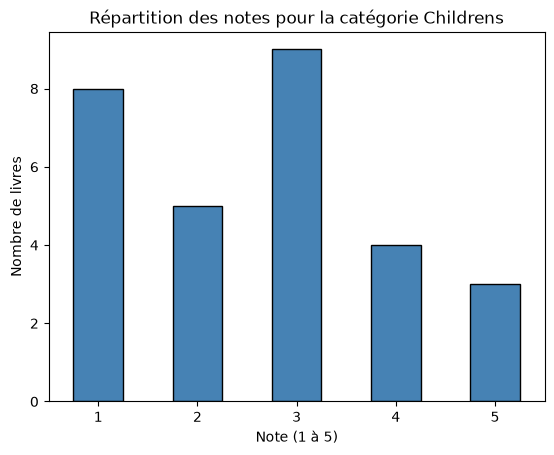

In [53]:
import matplotlib.pyplot as plt

repartition = df_childrens['note'].value_counts().sort_index()

repartition.plot.bar(color="steelblue", edgecolor="black", rot=0)
plt.title("Répartition des notes pour la catégorie Childrens")
plt.xlabel("Note (1 à 5)")
plt.ylabel("Nombre de livres")
plt.show()

In [54]:
df_childrens['categorie'].unique()

<StringArray>
['Childrens']
Length: 1, dtype: str

Il n'y a donc qu'une seul valeur das la colonne 'categorie'.

# Partie 8 - Export

In [55]:
df_childrens.to_csv("../data/childrens.csv", index=False)
print("CSV enregistré : ../data/childrens.csv")

CSV enregistré : ../data/childrens.csv
